# CMPE 258 — Shift-decomposed evaluation harness

**Smitha Soman** · audio deepfake detection project

A single pooled error rate hides *which* kind of change breaks a detector. This
notebook splits the ASVspoof 5 evaluation set into slices — by the generator that
produced the spoof, by the codec applied afterwards, and by whether an adversarial
filter was added — and measures each detector separately on every slice.

Nothing here touches audio. It works entirely from **score files**: one row per
audio file holding the detector's output. Shriya produced the AASIST scores,
Zahira the XLS-R scores. This notebook turns those into the results table.

Run the cells in order.

## Connect to Google Drive

The score files live in shared Drive folders. This links the notebook to Drive so
it can read them. A popup will ask for permission.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Check which folders are visible

A folder someone shared with you only appears here if you've added a shortcut to
it in My Drive (in Drive: right-click the folder → Organize → Add shortcut → My
Drive). This prints what's visible, so we can confirm `shriya_aasist` and `XLS-R`
are both there before going further.

In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'CMPE 252 - AI and data engineering', 'CMPE 294 - CMPE Seminar', 'CMPE 257 - Machine Learning', 'CMPE 258 - Deep Learning', 'SEM 1', 'Final Year Project', 'Internship', "Master's project", 'Text_to_Sql', 'kangaroo paper.gdoc', 'Smitha_Soman_Resume_AI_Systems_Robotics.pdf', 'MySJSU_ Unofficial Transcript.pdf', 'ALPR_Presentation_Updated.gslides', 'HW1_Language_Models', 'shriya_aasist']


## Confirm the files are actually reachable

Lists what's inside each of Shriya's subfolders. If this runs cleanly the paths
are correct and everything below will load.

In [ ]:
SHRIYA_DIR = '/content/drive/MyDrive/shriya_aasist'
for sub in ['scores', 'keys', 'splits', 'metrics', 'dfadd']:
    print(sub, '->', os.listdir(f'{SHRIYA_DIR}/{sub}'))

scores -> ['parts', 'aasist_dev.tsv', 'aasist_eval.tsv', 'aasist_train_heldout_ref.tsv', 'aasist_dfadd.tsv']
keys -> ['ASVspoof5.eval.track_1.tsv', 'eval_cm_keys.tsv', 'train_cm_keys.tsv', 'dev_cm_keys.tsv']
splits -> ['train_heldout_speakers.txt', 'train_kept_speakers.txt', 'train_heldout_files.tsv']
metrics -> ['aasist_metrics.json']
dfadd -> ['dfadd_prep_log.txt', 'dfadd_test_protocol.tsv', 'dfadd_summary.txt', 'dfadd_test_16k.tar']


## Step 1 - Load the scores and check nothing is broken

Loads two things and joins them: the **evaluation protocol**, which says what each
audio file really is (real or fake, which attack, which codec, which speaker), and
the **AASIST scores**, which say what the detector thought.

Then it checks the things that would quietly ruin every later number — are there
the expected 680,774 rows, are any filenames duplicated, does every score find a
matching label, is the score column the one we think it is.

It also recomputes the overall error rate with our own code and compares it against
the number the official ASVspoof scoring package gave Shriya. Those have to match.
The confidence intervals later need thousands of repeat calculations and the
official package is far too slow for that, so we need our own fast version to be
provably identical first.

The second half prints what is actually in the protocol — the codec values, the
attack labels, how files are grouped — so the slices get defined from the real data
rather than from what the proposal assumed.

In [ ]:
"""
CMPE 258 - shift-decomposed evaluation harness
STEP 1: load, validate, explore.

Paste this into a Colab cell (with Shriya's folder mounted) and run it.
It touches no audio and needs no GPU. Runtime is a couple of minutes.

What it does:
  1. Loads the eval protocol and the AASIST scores from Shriya's Drive folder.
  2. Validates them: row counts, join coverage, duplicates, score convention.
  3. Implements EER in numpy and checks it against Shriya's official-package
     numbers. This matters: the bootstrap needs ~1000 EER calls per slice, and
     the official package is too slow for that. Once our fast EER reproduces
     her 28.11% exactly, we can use it everywhere and still claim official
     metrics.
  4. Prints what is actually in the protocol - codec values, attack tags, the
     attack x codec grid - so the slice definitions come from the data rather
     than from the proposal.

Nothing here is written back to Drive. It is read-only.
"""

import json
import os

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Paths. SHRIYA_DIR is her shared folder; in Colab, "Shared with me" folders
# need a shortcut added to your own Drive before they appear under MyDrive.
# Right-click the folder in Drive -> Organize -> Add shortcut -> My Drive.
# --------------------------------------------------------------------------
SHRIYA_DIR = '/content/drive/MyDrive/shriya_aasist'

PROTO_EVAL = f'{SHRIYA_DIR}/keys/ASVspoof5.eval.track_1.tsv'
SCORES_EVAL = f'{SHRIYA_DIR}/scores/aasist_eval.tsv'
SCORES_DEV = f'{SHRIYA_DIR}/scores/aasist_dev.tsv'
SCORES_DFADD = f'{SHRIYA_DIR}/scores/aasist_dfadd.tsv'
SCORES_REF = f'{SHRIYA_DIR}/scores/aasist_train_heldout_ref.tsv'
METRICS_JSON = f'{SHRIYA_DIR}/metrics/aasist_metrics.json'

# Shriya's protocol column names and read settings - keep identical to hers.
PROTO_COLS = ['SPEAKER_ID', 'FLAC_FILE_NAME', 'SPEAKER_GENDER', 'CODEC', 'CODEC_Q',
              'CODEC_SEED', 'ATTACK_TAG', 'ATTACK_LABEL', 'KEY', 'TMP']

EXPECTED_EVAL_ROWS = 680774
EXPECTED_EVAL_BONAFIDE = 138688


# ==========================================================================
# EER, the standard ASVspoof implementation. Scores are bona fide logits,
# so higher means more likely real: bona fide are the target class.
# ==========================================================================
def det_curve(target_scores, nontarget_scores):
    n = target_scores.size + nontarget_scores.size
    all_scores = np.concatenate((target_scores, nontarget_scores))
    labels = np.concatenate((np.ones(target_scores.size), np.zeros(nontarget_scores.size)))
    order = np.argsort(all_scores, kind='mergesort')
    labels = labels[order]
    tar_sums = np.cumsum(labels)
    non_sums = nontarget_scores.size - (np.arange(1, n + 1) - tar_sums)
    frr = np.concatenate((np.atleast_1d(0), tar_sums / target_scores.size))
    far = np.concatenate((np.atleast_1d(1), non_sums / nontarget_scores.size))
    thr = np.concatenate((np.atleast_1d(all_scores[order[0]] - 0.001), all_scores[order]))
    return frr, far, thr


def compute_eer(target_scores, nontarget_scores):
    """Returns EER as a fraction (multiply by 100 for a percentage)."""
    if target_scores.size == 0 or nontarget_scores.size == 0:
        return np.nan
    frr, far, _ = det_curve(target_scores, nontarget_scores)
    i = np.argmin(np.abs(frr - far))
    return float(np.mean((frr[i], far[i])))


def eer_from_frame(df, score_col='cm-score', key_col='KEY'):
    tar = df.loc[df[key_col] == 'bonafide', score_col].to_numpy()
    non = df.loc[df[key_col] == 'spoof', score_col].to_numpy()
    return compute_eer(tar, non)


# ==========================================================================
def load():
    print('LOADING')
    print('-------')
    proto = pd.read_csv(PROTO_EVAL, sep=r'\s+', header=None,
                        names=PROTO_COLS, dtype=str)
    proto['filename'] = proto['FLAC_FILE_NAME']
    print(f'  protocol   {len(proto):>8,} rows')

    scores = pd.read_csv(SCORES_EVAL, sep='\t', dtype={'filename': str})
    print(f'  scores     {len(scores):>8,} rows   columns: {list(scores.columns)}')
    return proto, scores


def validate(proto, scores):
    print('\nVALIDATION')
    print('----------')
    ok = True

    def check(label, condition, detail=''):
        nonlocal ok
        mark = 'PASS' if condition else 'FAIL'
        if not condition:
            ok = False
        print(f'  [{mark}] {label}{("  " + detail) if detail else ""}')

    check('protocol row count', len(proto) == EXPECTED_EVAL_ROWS,
          f'{len(proto):,} (expected {EXPECTED_EVAL_ROWS:,})')
    check('score row count', len(scores) == EXPECTED_EVAL_ROWS,
          f'{len(scores):,}')
    check('no duplicate filenames in scores',
          not scores.filename.duplicated().any(),
          f'{int(scores.filename.duplicated().sum())} duplicates')
    check('no duplicate filenames in protocol',
          not proto.filename.duplicated().any(),
          f'{int(proto.filename.duplicated().sum())} duplicates')

    # The claim in Shriya's README: cm-score IS the bona fide logit.
    if 'logit_bonafide' in scores.columns:
        same = np.allclose(scores['cm-score'], scores['logit_bonafide'])
        check('cm-score == logit_bonafide', same,
              'convention confirmed' if same else 'THESE DIFFER - stop and check')

    merged = scores.merge(proto[['filename', 'KEY', 'SPEAKER_ID', 'CODEC',
                                 'CODEC_SEED', 'ATTACK_TAG', 'ATTACK_LABEL']],
                          on='filename', how='inner')
    coverage = len(merged) / len(scores) if len(scores) else 0
    check('join coverage is 100%', len(merged) == len(scores),
          f'{coverage:.4%} ({len(merged):,} of {len(scores):,})')
    check('bona fide count', int((merged.KEY == 'bonafide').sum()) == EXPECTED_EVAL_BONAFIDE,
          f'{int((merged.KEY == "bonafide").sum()):,}')
    check('scores are finite', np.isfinite(merged['cm-score']).all())

    return merged, ok


def self_check(merged):
    """Our numpy EER must reproduce Shriya's official-package number."""
    print('\nSELF-CHECK  (our EER vs. the official evaluation package)')
    print('---------------------------------------------------------')
    ours = 100 * eer_from_frame(merged)
    print(f'  our EER, eval pooled      {ours:6.2f}%')

    if os.path.exists(METRICS_JSON):
        official = json.load(open(METRICS_JSON))
        theirs = official.get('eval_pooled', {}).get('EER_%')
        if theirs is not None:
            print(f'  Shriya, official package  {theirs:6.2f}%')
            delta = abs(ours - theirs)
            if delta < 0.02:
                print('  [PASS] match. Use the fast EER for the bootstrap.')
            elif delta < 0.2:
                print(f'  [WARN] differ by {delta:.3f} points - small enough to be')
                print('         threshold-grid granularity, but report the official')
                print('         package numbers in the paper, not these.')
            else:
                print(f'  [FAIL] differ by {delta:.3f} points. Something is wrong with')
                print('         the join or the score column. Resolve before slicing.')
        else:
            print('  (eval_pooled not in the metrics file)')
    else:
        print('  (metrics file not found; skipping comparison)')
    return ours


def explore(merged):
    print('\nWHAT IS ACTUALLY IN THE EVAL PROTOCOL')
    print('------------------------------------')
    print(f'  speakers          {merged.SPEAKER_ID.nunique()}')
    print(f'  codec values      {sorted(merged.CODEC.unique())}')
    print(f'  attack labels     {sorted(merged.ATTACK_LABEL.unique())}')
    n_tags = merged.ATTACK_TAG.nunique()
    print(f'  attack tags       {n_tags} distinct')

    print('\n  files per codec')
    for codec, n in merged.CODEC.value_counts().sort_index().items():
        bona = int((merged.loc[merged.CODEC == codec, 'KEY'] == 'bonafide').sum())
        print(f'    {codec:<12} {n:>8,}   ({bona:,} bona fide)')

    print('\n  files per attack (spoof only, top 40 by count)')
    spoof = merged[merged.KEY == 'spoof']
    for tag, n in spoof.ATTACK_TAG.value_counts().head(40).items():
        print(f'    {tag:<12} {n:>8,}')

    print('\n  attack x codec grid (spoof only, first 12 attacks)')
    grid = pd.crosstab(spoof.ATTACK_TAG, spoof.CODEC)
    print(grid.head(12).to_string())

    print('\n  CODEC_SEED - this is what pairs a coded utterance with its C00 original')
    print(f'    distinct values   {merged.CODEC_SEED.nunique():,}')
    counts = merged.CODEC_SEED.value_counts()
    print(f'    files per seed    min {counts.min()}, median {int(counts.median())}, max {counts.max()}')
    print('    (a seed shared across codec conditions = the same source utterance)')


def per_attack_table(merged, top=15):
    """EER per attack, each against the same bona fide pool. A first look at
    which generators hurt, before slices are formally defined."""
    if 'C00' not in set(merged.CODEC):
        print('\n  (no C00 in this protocol - codec labels are '
              f'{sorted(merged.CODEC.unique())[:6]}; skipping the per-attack table)')
        return None
    print('\n  EER PER ATTACK  (vs. all bona fide at C00, uncoded)')
    c00 = merged[merged.CODEC == 'C00']
    bona = c00[c00.KEY == 'bonafide']
    rows = []
    for tag in sorted(c00.loc[c00.KEY == 'spoof', 'ATTACK_TAG'].unique()):
        sub = pd.concat([bona, c00[(c00.ATTACK_TAG == tag) & (c00.KEY == 'spoof')]])
        rows.append({'attack': tag, 'n_spoof': int((sub.KEY == 'spoof').sum()),
                     'EER_%': round(100 * eer_from_frame(sub), 2)})
    out = pd.DataFrame(rows).sort_values('EER_%', ascending=False)
    print(out.head(top).to_string(index=False))
    return out


def main():
    proto, scores = load()
    merged, ok = validate(proto, scores)
    if not ok:
        print('\nSome checks failed. Fix those before building slices.')
    self_check(merged)
    explore(merged)
    per_attack_table(merged)
    print('\nDONE. Paste this whole output back and we build the slices from it.')
    return merged


if __name__ == '__main__':
    merged = main()

LOADING
-------
  protocol    680,774 rows
  scores      680,774 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']

VALIDATION
----------
  [PASS] protocol row count  680,774 (expected 680,774)
  [PASS] score row count  680,774
  [PASS] no duplicate filenames in scores  0 duplicates
  [PASS] no duplicate filenames in protocol  0 duplicates
  [PASS] cm-score == logit_bonafide  convention confirmed
  [PASS] join coverage is 100%  100.0000% (680,774 of 680,774)
  [PASS] bona fide count  138,688
  [PASS] scores are finite

SELF-CHECK  (our EER vs. the official evaluation package)
---------------------------------------------------------
  our EER, eval pooled       28.11%
  Shriya, official package   28.11%
  [PASS] match. Use the fast EER for the bootstrap.

WHAT IS ACTUALLY IN THE EVAL PROTOCOL
------------------------------------
  speakers          737
  codec values      ['-', 'C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07', 'C08', 'C09', 'C10', 'C11']
  attack

## Step 2 — Work out how the protocol groups files

Three questions:

1. **What are the AC1 / AC2 / AC3 labels?** They turned out not to be the attack
   identifier — that lives in a different column. Worth knowing before slicing on
   the wrong thing.
2. **Can a compressed file be traced back to the original uncompressed version of
   the same utterance?** This matters a lot. Comparing one utterance with and
   without a codec is far stronger evidence than comparing two different sets of
   files.
3. **A first rough look** at how much each generator and each codec hurts.

In [ ]:
"""
CMPE 258 - evaluation harness
STEP 2: find out how the eval protocol really groups files, then take a first
        look at the generator and codec shifts.

Run this in the same notebook, after step 1 (it reuses `merged`).
Read-only, no audio, no GPU.

Three questions it answers:
  Q1. What are AC1 / AC2 / AC3?  (ATTACK_TAG vs ATTACK_LABEL)
  Q2. Can a coded file be paired with its uncoded original?  The proposal
      assumed CODEC_SEED does this. Step 1 showed median group size 1, so it
      probably does not. This checks every candidate pairing key and says
      plainly whether paired analysis is possible.
  Q3. What do the two shifts look like before any formal slicing?
"""

import numpy as np
import pandas as pd

UNCODED = '-'          # step 1 showed the uncoded condition is '-', not 'C00'
ATTACK = 'ATTACK_LABEL'  # the real attack identifier; ATTACK_TAG is something else


# ---------------------------------------------------------------- Q1
def what_are_the_tags(m):
    print('Q1. ATTACK_TAG vs ATTACK_LABEL')
    print('==============================')
    ct = pd.crosstab(m[ATTACK], m.ATTACK_TAG)
    print(ct.to_string())
    print('\n  Read this as: which attacks fall under each AC group. If each')
    print('  attack sits in exactly one AC, the ACs are a coarser grouping of')
    print('  attacks and we can ignore them. If an attack is spread across')
    print('  several ACs, ATTACK_TAG encodes something else (likely a codec or')
    print('  condition grouping) and is worth understanding before slicing.')

    spread = (ct > 0).sum(axis=1)
    multi = spread[spread > 1]
    if len(multi):
        print(f'\n  {len(multi)} attack(s) appear under more than one AC:')
        print('   ', dict(multi))
    else:
        print('\n  Every attack sits in exactly one AC group.')


# ---------------------------------------------------------------- Q2
def can_we_pair(m):
    print('\n\nQ2. CAN CODED FILES BE PAIRED WITH THEIR UNCODED ORIGINAL?')
    print('==========================================================')

    uncoded = m[m.CODEC == UNCODED]
    coded = m[m.CODEC != UNCODED]
    print(f'  uncoded files   {len(uncoded):>8,}')
    print(f'  coded files     {len(coded):>8,}')
    print(f'  ratio           {len(coded) / max(1, len(uncoded)):.2f} coded per uncoded')

    # --- CODEC_SEED, the key the proposal assumed ---
    print('\n  CODEC_SEED group sizes among CODED files only:')
    sizes = coded.CODEC_SEED.value_counts()
    dist = sizes.value_counts().sort_index()
    for size, n in dist.head(12).items():
        print(f'    {n:>8,} seeds cover exactly {size} file(s)')
    print(f'    distinct seeds among coded files: {coded.CODEC_SEED.nunique():,}')

    shared = sizes[sizes > 1]
    if len(shared):
        print(f'\n  {len(shared):,} seeds cover more than one coded file. Example:')
        example = shared.index[0]
        cols = ['filename', 'SPEAKER_ID', 'CODEC', ATTACK, 'KEY', 'CODEC_SEED']
        print(coded[coded.CODEC_SEED == example][cols].to_string(index=False))
        print('\n  If those rows are the SAME utterance under DIFFERENT codecs,')
        print('  CODEC_SEED pairs coded files with each other (but still not with')
        print('  the uncoded original, which carries a different seed value).')
    else:
        print('\n  No coded seed covers more than one file: CODEC_SEED is unique')
        print('  per file and cannot pair anything.')

    # --- does any seed appear in BOTH coded and uncoded? ---
    overlap = set(coded.CODEC_SEED.unique()) & set(uncoded.CODEC_SEED.unique())
    print(f'\n  seeds shared between coded and uncoded files: {len(overlap)}')
    if not overlap:
        print('  -> CODEC_SEED cannot link a coded file to its uncoded original.')

    # --- filenames: do coded and uncoded share a stem? ---
    print('\n  SAMPLE FILENAMES')
    print(f'    uncoded : {list(uncoded.filename.head(5))}')
    for c in sorted(coded.CODEC.unique())[:3]:
        print(f'    {c:<8}: {list(coded[coded.CODEC == c].filename.head(5))}')
    print('\n  If coded names are a transformation of an uncoded name (same stem,')
    print('  added suffix), we can pair on the stem. If they are unrelated IDs,')
    print('  no utterance-level pairing exists and the codec slice must be')
    print('  compared at the group level instead.')

    # --- speaker + attack as a coarser matched comparison ---
    print('\n  FALLBACK: speaker x attack coverage')
    key = ['SPEAKER_ID', ATTACK]
    u_keys = set(map(tuple, uncoded[key].drop_duplicates().to_numpy()))
    c_keys = set(map(tuple, coded[key].drop_duplicates().to_numpy()))
    both = u_keys & c_keys
    print(f'    speaker x attack cells, uncoded : {len(u_keys):,}')
    print(f'    speaker x attack cells, coded   : {len(c_keys):,}')
    print(f'    present in both                 : {len(both):,} '
          f'({len(both) / max(1, len(u_keys)):.1%} of uncoded cells)')
    print('    -> if this is high, the codec effect can be measured within')
    print('       speaker and attack even without utterance-level pairing.')


# ---------------------------------------------------------------- EER helpers
def det_curve(t, n_):
    n = t.size + n_.size
    s = np.concatenate((t, n_))
    lab = np.concatenate((np.ones(t.size), np.zeros(n_.size)))
    o = np.argsort(s, kind='mergesort')
    lab = lab[o]
    ts = np.cumsum(lab)
    ns = n_.size - (np.arange(1, n + 1) - ts)
    frr = np.concatenate((np.atleast_1d(0), ts / t.size))
    far = np.concatenate((np.atleast_1d(1), ns / n_.size))
    return frr, far


def eer_pct(df):
    t = df.loc[df.KEY == 'bonafide', 'cm-score'].to_numpy()
    n_ = df.loc[df.KEY == 'spoof', 'cm-score'].to_numpy()
    if t.size == 0 or n_.size == 0:
        return np.nan
    frr, far = det_curve(t, n_)
    i = np.argmin(np.abs(frr - far))
    return 100 * float(np.mean((frr[i], far[i])))


# ---------------------------------------------------------------- Q3
def first_look(m):
    print('\n\nQ3. FIRST LOOK AT THE TWO SHIFTS')
    print('================================')

    unc = m[m.CODEC == UNCODED]
    bona_unc = unc[unc.KEY == 'bonafide']

    print('\n  GENERATOR SHIFT - EER per attack, uncoded only,')
    print('  each attack scored against the same uncoded bona fide pool')
    rows = []
    for a in sorted(unc.loc[unc.KEY == 'spoof', ATTACK].unique()):
        sub = pd.concat([bona_unc, unc[(unc[ATTACK] == a) & (unc.KEY == 'spoof')]])
        rows.append({'attack': a,
                     'n_spoof': int((sub.KEY == 'spoof').sum()),
                     'speakers': sub.SPEAKER_ID.nunique(),
                     'EER_%': round(eer_pct(sub), 2)})
    gen = pd.DataFrame(rows).sort_values('EER_%', ascending=False)
    print(gen.to_string(index=False))
    print(f'\n  pooled uncoded EER: {eer_pct(unc):.2f}%')

    print('\n  CODEC SHIFT - EER per codec condition')
    print('  (each codec scored on its own files: bona fide and spoof both coded)')
    rows = []
    for c in sorted(m.CODEC.unique()):
        sub = m[m.CODEC == c]
        rows.append({'codec': c, 'n_files': len(sub),
                     'n_bonafide': int((sub.KEY == 'bonafide').sum()),
                     'EER_%': round(eer_pct(sub), 2)})
    cod = pd.DataFrame(rows)
    print(cod.to_string(index=False))

    print('\n  ADVERSARIAL - the Malafide and Malacopula attacks named in the')
    print('  proposal, uncoded, against the uncoded bona fide pool')
    adversarial = {'A18': 'Malafide (from A17)', 'A20': 'Malafide (from A12)',
                   'A23': 'Malafide (from A09)', 'A30': 'Malafide (from A17)',
                   'A27': 'Malacopula', 'A31': 'Malacopula', 'A32': 'Malacopula'}
    rows = []
    for a, what in adversarial.items():
        sel = unc[(unc[ATTACK] == a) & (unc.KEY == 'spoof')]
        if not len(sel):
            rows.append({'attack': a, 'kind': what, 'n_spoof': 0, 'EER_%': np.nan})
            continue
        sub = pd.concat([bona_unc, sel])
        rows.append({'attack': a, 'kind': what, 'n_spoof': len(sel),
                     'EER_%': round(eer_pct(sub), 2)})
    print(pd.DataFrame(rows).to_string(index=False))

    print('\n  ATTACK x CODEC coverage (rows = attacks, columns = codecs)')
    print(pd.crosstab(m[ATTACK], m.CODEC).to_string())

    return gen, cod


def main(m):
    what_are_the_tags(m)
    can_we_pair(m)
    gen, cod = first_look(m)
    print('\n\nDONE. Paste the output back; next step is the formal slices and')
    print('the speaker-level bootstrap.')
    return gen, cod


if __name__ == '__main__':
    try:
        gen_table, codec_table = main(merged)   # noqa: F821  (from step 1)
    except NameError:
        print('Run step 1 first in this notebook - this script needs `merged`.')

Q1. ATTACK_TAG vs ATTACK_LABEL
ATTACK_TAG         -    AC1    AC2   AC3
ATTACK_LABEL                            
A17                0  14726  12654  7034
A18                0  14744  12312  7312
A19                0  12924  11038  6898
A20                0  13224  11274  6946
A21                0  14756  12688  6916
A22                0  14654  12324  7402
A23                0  14158  12856  7378
A24                0  14706  12424  7208
A25                0  14308  13094  6984
A26                0  14538  12588  7260
A27                0  14688  12298  7198
A28                0  14886  12806  6722
A29                0  14630  12464  7314
A30                0  14564  12612  6930
A31                0  14496  12280  7180
A32                0  14258  12410  7022
bonafide      138688      0      0     0

  Read this as: which attacks fall under each AC group. If each
  attack sits in exactly one AC, the ACs are a coarser grouping of
  attacks and we can ignore them. If an attack is spread a

## Step 3 — Build the slices and put error bars on them

First it confirms that the `CODEC_SEED` column is the filename of the original
uncompressed file. It is — which means we have true matched pairs, and the codec
comparison can hold the utterance constant.

Then it builds the three slices (generator, adversarial, codec) and computes a 95%
confidence interval for each by resampling **speakers**, not individual files.
Files from the same speaker aren't independent of each other, so resampling files
would make the intervals look far narrower than they really are.

This produces the main results table.

In [ ]:
"""
CMPE 258 - evaluation harness
STEP 3: resolve the pairing question, build the formal slices, and put
        speaker-level bootstrap intervals on everything.

Run in the same notebook after steps 1 and 2. Needs `merged`.
Read-only on Drive; writes nothing. No audio, no GPU.

Part A  Is CODEC_SEED the filename of the uncoded source utterance?
        Step 2 compared coded seeds against uncoded SEEDS (all '-'), which was
        the wrong comparison. The right one is coded seed vs uncoded FILENAME.
Part B  The three slices, each against a matched reference.
Part C  Speaker-level bootstrap, then the results table.
"""

import numpy as np
import pandas as pd

UNCODED = '-'
ATTACK = 'ATTACK_LABEL'
SEED = 258
B_BOOT = 200        # raise to 1000 for the final run; 200 is fine while iterating

# Attack families, from the project README. A18/A20/A23/A30 are Malafide and
# A27/A31/A32 are Malacopula, so they are adversarial, not generator families.
FAMILIES = {
    'legacy unit selection': ['A19'],
    'zero-shot TTS':         ['A17', 'A21', 'A22', 'A28', 'A29'],
    'voice conversion':      ['A24', 'A25', 'A26'],
}
MALAFIDE = {'A18': 'A17', 'A30': 'A17', 'A20': None, 'A23': None}  # None = source is in dev
MALACOPULA = ['A27', 'A31', 'A32']


# ------------------------------------------------------------------ EER
def _eer(tar, non):
    if tar.size == 0 or non.size == 0:
        return np.nan
    n = tar.size + non.size
    s = np.concatenate((tar, non))
    lab = np.concatenate((np.ones(tar.size), np.zeros(non.size)))
    o = np.argsort(s, kind='mergesort')
    lab = lab[o]
    ts = np.cumsum(lab)
    ns = non.size - (np.arange(1, n + 1) - ts)
    frr = np.concatenate((np.atleast_1d(0.0), ts / tar.size))
    far = np.concatenate((np.atleast_1d(1.0), ns / non.size))
    i = np.argmin(np.abs(frr - far))
    return 100 * float((frr[i] + far[i]) / 2)


def eer_pct(df):
    return _eer(df.loc[df.KEY == 'bonafide', 'cm-score'].to_numpy(),
                df.loc[df.KEY == 'spoof', 'cm-score'].to_numpy())


# ------------------------------------------------------------------ Part A
def resolve_pairing(m):
    print('PART A. IS CODEC_SEED THE SOURCE UTTERANCE FILENAME?')
    print('=====================================================')
    uncoded = m[m.CODEC == UNCODED]
    coded = m[m.CODEC != UNCODED]

    uncoded_names = set(uncoded.filename)
    coded_seeds = set(coded.CODEC_SEED.unique())
    hit = coded_seeds & uncoded_names
    print(f'  distinct coded seeds              {len(coded_seeds):>9,}')
    print(f'  of those that are an uncoded file {len(hit):>9,}  '
          f'({len(hit) / max(1, len(coded_seeds)):.1%})')

    if len(hit) / max(1, len(coded_seeds)) > 0.5:
        print('\n  CONFIRMED: CODEC_SEED names the uncoded source utterance.')
        print('  True utterance-level pairing is available.')
        paired = True
    else:
        print('\n  NOT a filename link. Falling back to the fully-crossed codec')
        print('  subset, which still pairs codecs against each other.')
        paired = False

    if paired:
        # sanity: does a coded file agree with its source on speaker and attack?
        src = uncoded.set_index('filename')[['SPEAKER_ID', ATTACK, 'KEY', 'cm-score']]
        src.columns = ['src_speaker', 'src_attack', 'src_key', 'src_score']
        j = coded.join(src, on='CODEC_SEED', how='inner')
        print(f'\n  coded files linked to a source     {len(j):>9,} of {len(coded):,}')
        agree_spk = (j.SPEAKER_ID == j.src_speaker).mean()
        agree_att = (j[ATTACK] == j.src_attack).mean()
        print(f'  speaker agrees with source         {agree_spk:.2%}')
        print(f'  attack agrees with source          {agree_att:.2%}')
        if agree_spk > 0.99 and agree_att > 0.99:
            print('  -> consistent. Safe to use for paired codec analysis.')
        else:
            print('  -> INCONSISTENT. Do not use paired analysis; investigate.')
        return paired, j

    return paired, None


def crossed_subset(m):
    """The 11-codec fully crossed subset: source utterances encoded under
    every codec. Cleanest possible codec comparison."""
    coded = m[m.CODEC != UNCODED]
    n_codecs = coded.CODEC.nunique()
    sizes = coded.CODEC_SEED.value_counts()
    full = sizes[sizes == n_codecs].index
    sub = coded[coded.CODEC_SEED.isin(full)]
    print(f'\n  FULLY CROSSED SUBSET: {len(full):,} source utterances x '
          f'{n_codecs} codecs = {len(sub):,} files')
    return sub


# ------------------------------------------------------------------ Part C
def bootstrap_eer(df, b=B_BOOT, seed=SEED):
    """95% CI by resampling SPEAKERS with replacement (not utterances:
    utterances from one speaker are not independent)."""
    spk = df.SPEAKER_ID.to_numpy()
    sc = df['cm-score'].to_numpy()
    isb = (df.KEY == 'bonafide').to_numpy()
    uniq, inv = np.unique(spk, return_inverse=True)
    tar_by = [sc[(inv == i) & isb] for i in range(len(uniq))]
    non_by = [sc[(inv == i) & ~isb] for i in range(len(uniq))]

    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(b):
        pick = rng.integers(0, len(uniq), len(uniq))
        t = np.concatenate([tar_by[i] for i in pick])
        n_ = np.concatenate([non_by[i] for i in pick])
        v = _eer(t, n_)
        if np.isfinite(v):
            vals.append(v)
    if not vals:
        return np.nan, np.nan
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def row(name, df, kind):
    lo, hi = bootstrap_eer(df)
    return {'slice': name, 'kind': kind,
            'n_spoof': int((df.KEY == 'spoof').sum()),
            'speakers': df.SPEAKER_ID.nunique(),
            'EER_%': round(eer_pct(df), 2),
            'ci_lo': round(lo, 2), 'ci_hi': round(hi, 2)}


# ------------------------------------------------------------------ Part B
def build_slices(m, crossed):
    print('\n\nPART B/C. SLICES WITH SPEAKER-LEVEL BOOTSTRAP')
    print('==============================================')
    print(f'  (bootstrap B={B_BOOT}; raise to 1000 for the final table)')
    unc = m[m.CODEC == UNCODED]
    bona = unc[unc.KEY == 'bonafide']
    out = []

    print('\n  reference...')
    out.append(row('ALL attacks, uncoded', unc, 'reference'))

    print('  generator families...')
    for fam, attacks in FAMILIES.items():
        sel = unc[(unc[ATTACK].isin(attacks)) & (unc.KEY == 'spoof')]
        if len(sel):
            out.append(row(f'{fam} ({"+".join(attacks)})',
                           pd.concat([bona, sel]), 'generator'))

    print('  adversarial...')
    for atk, src in MALAFIDE.items():
        sel = unc[(unc[ATTACK] == atk) & (unc.KEY == 'spoof')]
        if len(sel):
            label = f'Malafide {atk}' + (f' (from {src})' if src else ' (source in dev)')
            out.append(row(label, pd.concat([bona, sel]), 'adversarial'))
    sel = unc[(unc[ATTACK].isin(MALACOPULA)) & (unc.KEY == 'spoof')]
    if len(sel):
        out.append(row(f'Malacopula ({"+".join(MALACOPULA)})',
                       pd.concat([bona, sel]), 'adversarial'))

    print('  adversarial, source-matched (the clean comparison)...')
    for atk, src in MALAFIDE.items():
        if src is None:
            continue
        s_sel = unc[(unc[ATTACK] == src) & (unc.KEY == 'spoof')]
        a_sel = unc[(unc[ATTACK] == atk) & (unc.KEY == 'spoof')]
        if len(s_sel) and len(a_sel):
            out.append(row(f'  source {src} alone', pd.concat([bona, s_sel]), 'adv-paired'))
            out.append(row(f'  -> {atk} (adversarial)', pd.concat([bona, a_sel]), 'adv-paired'))

    print('  codec, on the fully crossed subset...')
    cb = crossed  # bona fide and spoof both coded, within this subset
    for c in sorted(cb.CODEC.unique()):
        out.append(row(f'codec {c}', cb[cb.CODEC == c], 'codec'))

    return pd.DataFrame(out)


def report(tab):
    print('\n\nRESULTS  (EER %, 95% speaker-level bootstrap CI)')
    print('=================================================')
    for kind in ['reference', 'generator', 'adversarial', 'adv-paired', 'codec']:
        part = tab[tab['kind'] == kind]
        if not len(part):
            continue
        print(f'\n{kind.upper()}')
        for _, r in part.iterrows():
            print(f"  {r['slice']:<40} {r['EER_%']:>6.2f}  "
                  f"[{r['ci_lo']:>6.2f}, {r['ci_hi']:>6.2f}]   "
                  f"n={r['n_spoof']:>7,}  spk={r['speakers']}")

    ref = tab[tab['kind'] == 'reference']['EER_%'].iloc[0] if len(tab[tab['kind'] == 'reference']) else np.nan
    print(f'\n  Reference (all attacks, uncoded): {ref:.2f}%')
    print('  A slice whose CI excludes the reference is a real effect.')
    print('  Compare the SPREAD within each shift type, not just the worst cell:')
    print('  that spread is what answers "which shift breaks detectors".')


def main(m):
    paired, joined = resolve_pairing(m)
    crossed = crossed_subset(m)
    tab = build_slices(m, crossed)
    report(tab)
    print('\n\nDONE. Paste the output back.')
    return tab, paired, joined


if __name__ == '__main__':
    try:
        results, is_paired, joined_df = main(merged)   # noqa: F821
    except NameError:
        print('Run step 1 first in this notebook - this script needs `merged`.')

PART A. IS CODEC_SEED THE SOURCE UTTERANCE FILENAME?
  distinct coded seeds                171,602
  of those that are an uncoded file   171,602  (100.0%)

  CONFIRMED: CODEC_SEED names the uncoded source utterance.
  True utterance-level pairing is available.

  coded files linked to a source       509,172 of 509,172
  speaker agrees with source         100.00%
  attack agrees with source          100.00%
  -> consistent. Safe to use for paired codec analysis.

  FULLY CROSSED SUBSET: 33,757 source utterances x 11 codecs = 371,327 files


PART B/C. SLICES WITH SPEAKER-LEVEL BOOTSTRAP
  (bootstrap B=200; raise to 1000 for the final table)

  reference...
  generator families...
  adversarial...
  adversarial, source-matched (the clean comparison)...
  codec, on the fully crossed subset...


RESULTS  (EER %, 95% speaker-level bootstrap CI)

REFERENCE
  ALL attacks, uncoded                      22.35  [ 21.72,  23.00]   n=136,453  spk=737

GENERATOR
  legacy unit selection (A19)         

## Save the results table

Colab wipes its local disk when the session ends, so this writes the table to Drive.

In [ ]:
results.to_csv('/content/drive/MyDrive/258_results_shift_table.csv', index=False)
print(results.to_string(index=False))

                              slice        kind  n_spoof  speakers  EER_%  ci_lo  ci_hi
               ALL attacks, uncoded   reference   136453       737  22.35  21.72  23.00
        legacy unit selection (A19)   generator     7760       737  60.55  59.27  61.86
zero-shot TTS (A17+A21+A22+A28+A29)   generator    43278       737   6.49   6.03   6.99
     voice conversion (A24+A25+A26)   generator    25955       737  10.86  10.25  11.53
            Malafide A18 (from A17) adversarial     8649       737  46.83  45.38  48.54
            Malafide A30 (from A17) adversarial     8593       737  34.25  32.37  36.07
       Malafide A20 (source in dev) adversarial     7917       737  49.05  47.70  50.48
       Malafide A23 (source in dev) adversarial     8651       737  18.84  17.75  20.05
           Malacopula (A27+A31+A32) adversarial    25650       737  16.72  15.49  17.93
                   source A17 alone  adv-paired     8662       737   3.54   3.04   4.00
               -> A18 (adversari

## Why does AASIST score *worse than random* on A19?

A19 came out at 60.55% equal error rate. Above 50% doesn't mean "bad" — it means
**backwards**. The detector is scoring those fakes as *more real* than genuine
human speech.

Three checks that this is real rather than a quirk of a few files:

- how often a real file outscores an A19 file (the AUC — below 0.5 means inverted)
- whether nearly every speaker shows it, or only a handful
- whether it survives audio compression

The proposed explanation: A19 is unit-selection synthesis, which stitches together
recorded chunks of real human speech. There is no neural vocoder, so there are no
vocoder artifacts for AASIST to find — and the stitched audio is *cleaner* than our
crowdsourced real recordings, which were not made in a studio.

SCORE DISTRIBUTIONS, UNCODED  (higher = detector thinks more real)
  bona fide              n= 35,149   p5    6.64  p25    8.51  median    9.79  p75   11.05  p95   13.00
  A19 (spoof)            n=  7,760   p5    7.83  p25    9.60  median   10.82  p75   12.05  p95   14.01
  A18 (spoof)            n=  8,649   p5    7.14  p25    8.52  median    9.51  p75   10.52  p95   11.92
  A26 (spoof)            n=  8,653   p5    2.59  p25    4.60  median    5.86  p75    7.04  p95    8.79
  A17 (spoof)            n=  8,662   p5   -0.38  p25    1.64  median    2.97  p75    4.17  p95    6.01
  A29 (spoof)            n=  8,659   p5   -4.96  p25   -3.02  median   -1.58  p75   -0.09  p95    2.01


AUC: P(bona fide scores above the attack)
  > 0.5 detector separates correctly | = 0.5 chance | < 0.5 INVERTED
attack    AUC  median_shift_vs_bonafide     verdict
   A19 0.3474                     1.025    INVERTED
   A18 0.5451                    -0.286 near chance
   A26 0.9333                    -3.933     co

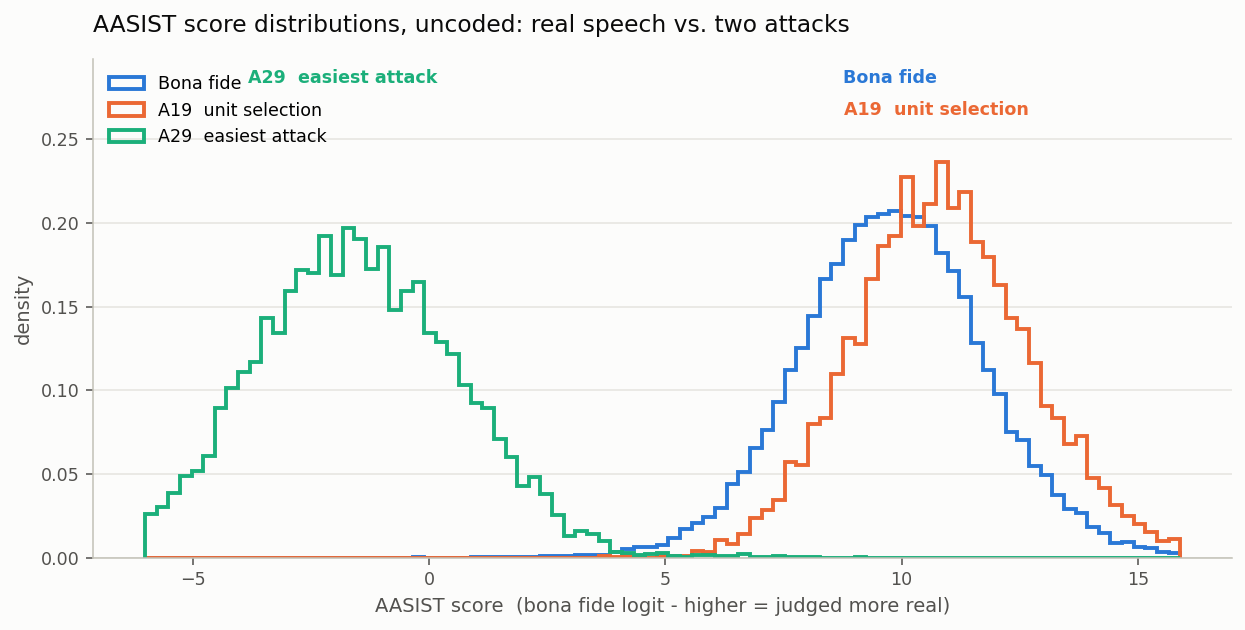

In [ ]:
"""
CMPE 258 - is the A19 result real, and does the "unit selection is recombined
real speech" explanation hold?

Run in the same notebook after step 1. Needs `merged`.

EER above 50% says the detector is worse than chance on A19, but EER alone does
not say WHY. Three different things produce a high EER and only one of them
supports the explanation:

  (a) A19 scores sit ABOVE bona fide        -> systematic inversion, story holds
  (b) A19 scores overlap bona fide heavily  -> the detector is just blind to it
  (c) a subset of speakers or files drives  -> an artifact, not a property of A19

The decisive number is AUC = P(a bona fide file scores higher than an A19 file).
Above 0.5 the detector has the right idea; at 0.5 it is guessing; below 0.5 it
is actively inverted. The per-speaker breakdown separates (a) from (c).
"""

import numpy as np
import pandas as pd

UNCODED = '-'
ATTACK = 'ATTACK_LABEL'
CONTEXT = ['A19', 'A18', 'A26', 'A17', 'A29']   # worst -> best, from step 3

# validated categorical hues (slots 1-3), all-pairs clean in light mode
C_BONA, C_A19, C_EASY = '#2a78d6', '#eb6834', '#1baf7a'


def auc_pos_over_neg(pos, neg):
    """P(a random `pos` value exceeds a random `neg` value), ties counted half."""
    from scipy.stats import rankdata
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    n1, n2 = len(pos), len(neg)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n2))


def describe(name, x):
    q = np.percentile(x, [5, 25, 50, 75, 95])
    print(f'  {name:<22} n={len(x):>7,}   '
          f'p5 {q[0]:>7.2f}  p25 {q[1]:>7.2f}  median {q[2]:>7.2f}  '
          f'p75 {q[3]:>7.2f}  p95 {q[4]:>7.2f}')


def main(m, make_plot=True, save_to=None):
    unc = m[m.CODEC == UNCODED]
    bona = unc.loc[unc.KEY == 'bonafide', 'cm-score'].to_numpy()

    print('SCORE DISTRIBUTIONS, UNCODED  (higher = detector thinks more real)')
    print('===================================================================')
    describe('bona fide', bona)
    for a in CONTEXT:
        x = unc.loc[(unc[ATTACK] == a) & (unc.KEY == 'spoof'), 'cm-score'].to_numpy()
        if len(x):
            describe(f'{a} (spoof)', x)

    print('\n\nAUC: P(bona fide scores above the attack)')
    print('=========================================')
    print('  > 0.5 detector separates correctly | = 0.5 chance | < 0.5 INVERTED')
    rows = []
    for a in CONTEXT:
        x = unc.loc[(unc[ATTACK] == a) & (unc.KEY == 'spoof'), 'cm-score'].to_numpy()
        if not len(x):
            continue
        a_auc = auc_pos_over_neg(bona, x)
        shift = float(np.median(x) - np.median(bona))
        verdict = ('INVERTED' if a_auc < 0.45 else
                   'near chance' if a_auc < 0.55 else 'correct')
        rows.append({'attack': a, 'AUC': round(a_auc, 4),
                     'median_shift_vs_bonafide': round(shift, 3),
                     'verdict': verdict})
    print(pd.DataFrame(rows).to_string(index=False))
    print('\n  median_shift > 0 means the attack scores HIGHER than real speech.')

    print('\n\nIS IT EVERY SPEAKER, OR A FEW?')
    print('===============================')
    a19 = unc[(unc[ATTACK] == 'A19') & (unc.KEY == 'spoof')]
    bona_rows = unc[unc.KEY == 'bonafide']
    per = []
    for spk, grp in a19.groupby('SPEAKER_ID'):
        b = bona_rows.loc[bona_rows.SPEAKER_ID == spk, 'cm-score'].to_numpy()
        if len(b) < 3 or len(grp) < 3:
            continue
        per.append({'speaker': spk,
                    'auc': auc_pos_over_neg(b, grp['cm-score'].to_numpy()),
                    'n_bona': len(b), 'n_a19': len(grp)})
    per = pd.DataFrame(per)
    if len(per):
        inverted = (per.auc < 0.5).mean()
        print(f'  speakers with enough files     {len(per)}')
        print(f'  speakers where A19 outscores   {inverted:.1%}')
        print(f'  per-speaker AUC  median {per.auc.median():.3f}   '
              f'p10 {per.auc.quantile(.10):.3f}   p90 {per.auc.quantile(.90):.3f}')
        if inverted > 0.9:
            print('  -> systematic across speakers. Not an artifact of a few files.')
        elif inverted > 0.6:
            print('  -> mostly systematic, but check the speakers that disagree.')
        else:
            print('  -> NOT systematic. A subset drives it; do not claim a')
            print('     property of unit selection until you know which files.')

    print('\n\nDOES IT SURVIVE CODECS?')
    print('========================')
    print('  If A19 stays inverted once coded, the cue is in the speech itself,')
    print('  not in a clean-recording artifact that compression destroys.')
    rows = []
    for c in sorted(m.CODEC.unique()):
        sub = m[m.CODEC == c]
        b = sub.loc[sub.KEY == 'bonafide', 'cm-score'].to_numpy()
        x = sub.loc[(sub[ATTACK] == 'A19') & (sub.KEY == 'spoof'), 'cm-score'].to_numpy()
        if len(b) and len(x):
            rows.append({'codec': c, 'n_a19': len(x),
                         'AUC': round(auc_pos_over_neg(b, x), 4)})
    print(pd.DataFrame(rows).to_string(index=False))

    if make_plot:
        plot(unc, bona, save_to)

    return per


def plot(unc, bona, save_to=None):
    import matplotlib.pyplot as plt

    a19 = unc.loc[(unc[ATTACK] == 'A19') & (unc.KEY == 'spoof'), 'cm-score'].to_numpy()
    easy = unc.loc[(unc[ATTACK] == 'A29') & (unc.KEY == 'spoof'), 'cm-score'].to_numpy()

    lo, hi = np.percentile(np.concatenate([bona, a19, easy]), [0.2, 99.8])
    bins = np.linspace(lo, hi, 90)

    fig, ax = plt.subplots(figsize=(9, 4.6), dpi=140)
    fig.patch.set_facecolor('#fcfcfb')
    ax.set_facecolor('#fcfcfb')

    series = [('Bona fide', bona, C_BONA),
              ('A19  unit selection', a19, C_A19),
              ('A29  easiest attack', easy, C_EASY)]
    peaks, top = [], 0.0
    for label, x, color in series:
        ax.hist(x, bins=bins, density=True, histtype='step',
                linewidth=2, color=color, label=label)
        h, e = np.histogram(x, bins=bins, density=True)
        peaks.append((label, float(e[np.argmax(h)]), color))
        top = max(top, float(h.max()))

    # Direct labels sit in a band above the curves, never on them (relief rule).
    # Stagger any two whose x positions are close enough to collide.
    ax.set_ylim(0, top * 1.26)
    span = bins[-1] - bins[0]
    placed = []
    for label, x, color in sorted(peaks, key=lambda p: p[1]):
        level = 0
        while any(abs(x - px) < 0.22 * span and lv == level for px, lv in placed):
            level += 1
        placed.append((x, level))
        ax.annotate(label, xy=(x, top * (1.19 - 0.08 * level)),
                    ha='center', va='bottom', fontsize=9,
                    color=color, fontweight='600')

    ax.set_xlabel('AASIST score  (bona fide logit - higher = judged more real)',
                  fontsize=10, color='#52514e')
    ax.set_ylabel('density', fontsize=10, color='#52514e')
    # Neutral title: rewrite it to state the finding once the numbers confirm it.
    ax.set_title('AASIST score distributions, uncoded: real speech vs. two attacks',
                 fontsize=12, color='#0b0b0b', loc='left', pad=14)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color('#c3c2b7')
    ax.tick_params(colors='#52514e', labelsize=9)
    fig.tight_layout()

    if save_to:
        fig.savefig(save_to, bbox_inches='tight', facecolor=fig.get_facecolor())
        print(f'\n  figure saved: {save_to}')
    plt.show()


if __name__ == '__main__':
    try:
        per_speaker = main(merged,  # noqa: F821
                           save_to='/content/drive/MyDrive/258_fig_a19_scores.png')
    except NameError:
        print('Run step 1 first in this notebook - this script needs `merged`.')

## Check Zahira's XLS-R scores

Her detector's development-set scores arrived. Before building anything on them:

- the same format checks as before (rows, duplicates, join coverage, score direction)
- **do the three random seeds agree with each other?** They were trained with three
  different initialisations. If the results swing wildly between them, nothing built
  on this detector can be trusted.
- a first head-to-head against AASIST on exactly the same files

In [ ]:
"""
CMPE 258 - dev-stage check on the XLS-R scores
==============================================

Run this before the eval scores land. Three jobs:

  1. VALIDATE   Zahira's score files, the same way we validated Shriya's.
                A format surprise is cheap to find now on a 6 MB dev file and
                expensive to find tonight on the eval set.
  2. SEEDS      Do the three seeds agree? Three seeds exist so this can be
                checked; if they disagree materially, every RQ2 claim built on
                the SSL column inherits that instability.
  3. HEAD-TO-HEAD  First architecture comparison. Both detectors scored the
                same 140,950 dev files (attacks A09-A16).

Self-contained: downloads the 19 MB protocol archive if the dev protocol is not
already on disk. No audio, no GPU.
"""

import glob
import os
import subprocess

import numpy as np
import pandas as pd

# --------------------------------------------------------------------- paths
SHRIYA_DIR = '/content/drive/MyDrive/shriya_aasist'
ZAHIRA_DIR = '/content/drive/MyDrive/XLS-R'        # adjust if the shortcut lands elsewhere
PROTO_DIR = '/content/asvspoof5_protocols'

AASIST_DEV = f'{SHRIYA_DIR}/scores/aasist_dev.tsv'
SEED_FILES = {258: f'{ZAHIRA_DIR}/scores/xlsr_dev_seed_258.tsv',
              259: f'{ZAHIRA_DIR}/scores/xlsr_dev_seed_259.tsv',
              260: f'{ZAHIRA_DIR}/scores/xlsr_dev_seed_260.tsv'}
COMBINED = f'{ZAHIRA_DIR}/scores/xlsr_dev.tsv'

PROTO_COLS = ['SPEAKER_ID', 'FLAC_FILE_NAME', 'SPEAKER_GENDER', 'CODEC', 'CODEC_Q',
              'CODEC_SEED', 'ATTACK_TAG', 'ATTACK_LABEL', 'KEY', 'TMP']
EXPECTED_DEV_ROWS = 140950
ZENODO = 'https://zenodo.org/records/14498691/files/ASVspoof5_protocols.tar.gz'


# ----------------------------------------------------------------------- EER
def _eer(tar, non):
    if tar.size == 0 or non.size == 0:
        return np.nan
    n = tar.size + non.size
    s = np.concatenate((tar, non))
    lab = np.concatenate((np.ones(tar.size), np.zeros(non.size)))
    o = np.argsort(s, kind='mergesort')
    lab = lab[o]
    ts = np.cumsum(lab)
    ns = non.size - (np.arange(1, n + 1) - ts)
    frr = np.concatenate((np.atleast_1d(0.0), ts / tar.size))
    far = np.concatenate((np.atleast_1d(1.0), ns / non.size))
    i = np.argmin(np.abs(frr - far))
    return 100 * float((frr[i] + far[i]) / 2)


def eer_pct(df, col='score'):
    return _eer(df.loc[df.KEY == 'bonafide', col].to_numpy(),
                df.loc[df.KEY == 'spoof', col].to_numpy())


def auc_pct(df, col='score'):
    """P(bona fide scores above spoof). Below 0.5 = inverted."""
    from scipy.stats import rankdata
    pos = df.loc[df.KEY == 'bonafide', col].to_numpy()
    neg = df.loc[df.KEY == 'spoof', col].to_numpy()
    if not len(pos) or not len(neg):
        return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))


# -------------------------------------------------------------------- loading
def dev_protocol():
    hits = glob.glob(os.path.join(PROTO_DIR, '**', 'ASVspoof5.dev.track_1.tsv'),
                     recursive=True)
    if not hits:
        print('  dev protocol not found locally; downloading (19 MB)...')
        os.makedirs(PROTO_DIR, exist_ok=True)
        tgz = '/content/ASVspoof5_protocols.tar.gz'
        subprocess.run(['wget', '-q', '-O', tgz, ZENODO], check=True)
        subprocess.run(['tar', '-xf', tgz, '-C', PROTO_DIR], check=True)
        os.remove(tgz)
        hits = glob.glob(os.path.join(PROTO_DIR, '**', 'ASVspoof5.dev.track_1.tsv'),
                         recursive=True)
    df = pd.read_csv(hits[0], sep=r'\s+', header=None, names=PROTO_COLS, dtype=str)
    df['filename'] = df['FLAC_FILE_NAME']
    return df


def read_scores(path, label):
    """Read a score file and normalise its score column to `score`.
    Prints the real columns, because a mismatch here is what breaks tonight."""
    df = pd.read_csv(path, sep='\t', dtype={'filename': str})
    cols = list(df.columns)
    candidates = ['cm-score', 'cm_score', 'score', 'logit_bonafide', 'bonafide']
    col = next((c for c in candidates if c in cols), None)
    if col is None:
        numeric = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
        col = numeric[0] if numeric else None
    print(f'  {label:<22} {len(df):>8,} rows   columns: {cols}')
    if col is None:
        print(f'    [FAIL] no usable score column in {label}')
        return None
    if col != 'cm-score':
        print(f'    [NOTE] using "{col}" as the score column')
    out = df[['filename', col]].rename(columns={col: 'score'})
    return out


# ------------------------------------------------------------------- sections
def validate(name, df, proto):
    ok = True

    def check(label, cond, detail=''):
        nonlocal ok
        if not cond:
            ok = False
        print(f'    [{"PASS" if cond else "FAIL"}] {label}{("  " + detail) if detail else ""}')

    print(f'\n  {name}')
    check('row count', len(df) == EXPECTED_DEV_ROWS,
          f'{len(df):,} (expected {EXPECTED_DEV_ROWS:,})')
    check('no duplicate filenames', not df.filename.duplicated().any(),
          f'{int(df.filename.duplicated().sum())} duplicates')
    m = df.merge(proto[['filename', 'KEY', 'SPEAKER_ID', 'ATTACK_LABEL']], on='filename')
    check('join coverage 100%', len(m) == len(df),
          f'{len(m):,} of {len(df):,}')
    check('scores finite', np.isfinite(m.score).all())
    e = eer_pct(m)
    a = auc_pct(m)
    print(f'    EER {e:6.2f}%   AUC {a:.4f}'
          + ('   [WARN] AUC < 0.5: scores may be sign-flipped' if a < 0.5 else ''))
    return m, ok


def identify_combined(seeds, combined):
    """Is xlsr_dev.tsv a 4th seed, a copy of one, or the mean of the three?
    Treating an average as a seed would understate the seed variance."""
    print('\n\n2. WHAT IS xlsr_dev.tsv?')
    print('=========================')
    base = combined[['filename', 'score']].rename(columns={'score': 'comb'})
    for s, df in seeds.items():
        j = base.merge(df[['filename', 'score']], on='filename')
        if np.allclose(j.comb, j.score, atol=1e-6):
            print(f'  identical to seed {s}. Treat it as that seed, not a 4th run.')
            return f'copy of seed {s}'
    stack = None
    for s, df in seeds.items():
        col = df[['filename', 'score']].rename(columns={'score': f's{s}'})
        stack = col if stack is None else stack.merge(col, on='filename')
    j = base.merge(stack, on='filename')
    mean = j[[c for c in j.columns if c.startswith('s')]].mean(axis=1)
    if np.allclose(j.comb, mean, atol=1e-4):
        print('  equals the MEAN of the three seeds (a seed-averaged ensemble).')
        print('  Use it as the headline SSL score, but compute seed variance')
        print('  from the three individual files, never from this one.')
        return 'mean of seeds'
    print('  matches neither a single seed nor their mean - ask Zahira what it is')
    print(f'  corr with seed mean: {np.corrcoef(j.comb, mean)[0, 1]:.6f}')
    return 'unknown'


def seed_agreement(seeds):
    print('\n\n3. DO THE THREE SEEDS AGREE?')
    print('=============================')
    rows = [{'seed': s, 'EER_%': round(eer_pct(df), 3), 'AUC': round(auc_pct(df), 4)}
            for s, df in seeds.items()]
    tab = pd.DataFrame(rows)
    print(tab.to_string(index=False))
    spread = tab['EER_%'].max() - tab['EER_%'].min()
    print(f'\n  EER spread across seeds: {spread:.3f} points '
          f'(mean {tab["EER_%"].mean():.2f}, sd {tab["EER_%"].std():.3f})')

    merged = None
    for s, df in seeds.items():
        col = df[['filename', 'score']].rename(columns={'score': f'seed_{s}'})
        merged = col if merged is None else merged.merge(col, on='filename')
    sc = merged[[c for c in merged.columns if c.startswith('seed_')]]
    print('\n  pairwise score correlation between seeds')
    print(sc.corr().round(4).to_string())

    if spread < 0.5:
        print('\n  -> seeds agree closely. The SSL column is stable; report the')
        print('     mean with the seed spread as a footnote.')
    elif spread < 2.0:
        print('\n  -> moderate spread. Report mean +/- spread everywhere, and do')
        print('     not claim a difference smaller than the spread itself.')
    else:
        print('\n  -> LARGE spread. The head is unstable across initialisations.')
        print('     Any RQ2 claim inherits this. Raise it with Zahira today.')
    return tab


def head_to_head(aasist, xlsr, proto):
    print('\n\n4. AASIST vs XLS-R ON DEV  (A09-A16, same 140,950 files)')
    print('=========================================================')
    print(f'  {"detector":<12} {"EER %":>8} {"AUC":>8}')
    print(f'  {"AASIST":<12} {eer_pct(aasist):>8.2f} {auc_pct(aasist):>8.4f}')
    print(f'  {"XLS-R":<12} {eer_pct(xlsr):>8.2f} {auc_pct(xlsr):>8.4f}')

    print('\n  per attack (each attack vs the full bona fide pool)')
    rows = []
    for name, df in [('AASIST', aasist), ('XLS-R', xlsr)]:
        bona = df[df.KEY == 'bonafide']
        for a in sorted(df.loc[df.KEY == 'spoof', 'ATTACK_LABEL'].unique()):
            sub = pd.concat([bona, df[(df.ATTACK_LABEL == a) & (df.KEY == 'spoof')]])
            rows.append({'detector': name, 'attack': a,
                         'n_spoof': int((sub.KEY == 'spoof').sum()),
                         'EER_%': round(eer_pct(sub), 2)})
    tab = pd.DataFrame(rows).pivot(index='attack', columns='detector', values='EER_%')
    tab['diff (XLS-R - AASIST)'] = (tab['XLS-R'] - tab['AASIST']).round(2)
    print(tab.to_string())
    print('\n  Negative diff = XLS-R is better on that attack. What matters for RQ2')
    print('  is whether the two detectors RANK the attacks the same way, not')
    print('  whether one is lower overall.')
    r = tab[['AASIST', 'XLS-R']].corr(method='spearman').iloc[0, 1]
    print(f'\n  Spearman rank correlation of per-attack difficulty: {r:.3f}')
    if r > 0.8:
        print('  -> the architectures find the same attacks hard. Early evidence')
        print('     that the failure modes are shared, not architecture-specific.')
    elif r > 0.4:
        print('  -> partially shared ordering. Worth a close look on the eval slices.')
    else:
        print('  -> the architectures fail on DIFFERENT attacks. That is the')
        print('     interesting answer to RQ2 if it holds on eval.')
    return tab


def main():
    print('1. LOAD AND VALIDATE')
    print('====================')
    proto = dev_protocol()
    print(f'  dev protocol           {len(proto):>8,} rows')

    aasist_raw = read_scores(AASIST_DEV, 'AASIST dev')
    seeds_raw = {s: read_scores(p, f'XLS-R seed {s}') for s, p in SEED_FILES.items()}
    comb_raw = read_scores(COMBINED, 'XLS-R combined')

    aasist, _ = validate('AASIST dev', aasist_raw, proto)
    seeds = {}
    for s, df in seeds_raw.items():
        seeds[s], _ = validate(f'XLS-R seed {s}', df, proto)
    comb, _ = validate('XLS-R combined', comb_raw, proto)

    identify_combined(seeds, comb)
    seed_agreement(seeds)
    head_to_head(aasist, comb, proto)

    print('\n\nDONE. Paste the output back.')
    return aasist, seeds, comb


if __name__ == '__main__':
    aasist_dev, xlsr_seeds, xlsr_comb = main()

1. LOAD AND VALIDATE
  dev protocol            140,950 rows
  AASIST dev              140,950 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']
  XLS-R seed 258          140,950 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']
  XLS-R seed 259          140,950 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']
  XLS-R seed 260          140,950 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']
  XLS-R combined          140,950 rows   columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']

  AASIST dev
    [PASS] row count  140,950 (expected 140,950)
    [PASS] no duplicate filenames  0 duplicates
    [PASS] join coverage 100%  140,950 of 140,950
    [PASS] scores finite
    EER  15.20%   AUC 0.8794

  XLS-R seed 258
    [PASS] row count  140,950 (expected 140,950)
    [PASS] no duplicate filenames  0 duplicates
    [PASS] join coverage 100%  140,950 of 140,950
    [PASS] scores fi

## Reconnect Drive after renaming a shortcut

Colab caches the folder listing when it mounts, so a shortcut renamed afterwards
still shows the old name until you force a remount.

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## Does AASIST get any other attack backwards?

Checks every development-set attack, under both detectors, for the same inversion
found on A19.

It finds one: **AASIST is inverted on A12 too, and only A12. XLS-R is inverted on
nothing.**

That matters because A12 and A19 are the only two attacks in the entire benchmark
built by waveform concatenation rather than a neural vocoder. Every other attack
uses HiFi-GAN, BigVGAN, WaveGrad, WaveGlow or WaveNet. So the explanation proposed
for A19 correctly picks out the one other attack it should apply to — found on an
attack we hadn't looked at when the explanation was written.

1. INVERSION SCAN - AUC per attack, both detectors
  AUC = P(bona fide outscores the attack). < 0.5 means INVERTED.

detector  AASIST   XLS-R
attack                  
A09       0.9888  0.9999
A10       0.9890  1.0000
A11       0.9930  0.9877
A12       0.1939  0.9988
A13       0.9614  0.9997
A14       0.9986  1.0000
A15       0.9640  0.9999
A16       0.9467  1.0000

  INVERTED (AUC below 0.5):
    AASIST   A12   AUC 0.1939   scores +2.28 vs bona fide median   n=13,702

  Count of inverted attacks per detector:
    AASIST   1 of 8
    XLS-R    0 of 8

  One architecture inverting where the other does not is a
  qualitative difference, not a difference of degree. That is the
  RQ2 claim worth making.


2. DEEP DIVE ON A12

  AASIST   AUC 0.1939   INVERTED
    bona fide    n= 31,334   p5    6.20  p25    8.24  median    9.63  p75   10.97  p95   12.86
    A12          n= 13,702   p5    8.98  p25   10.74  median   11.91  p75   13.11  p95   14.98
    speakers checked 386;  99.2% show the inver

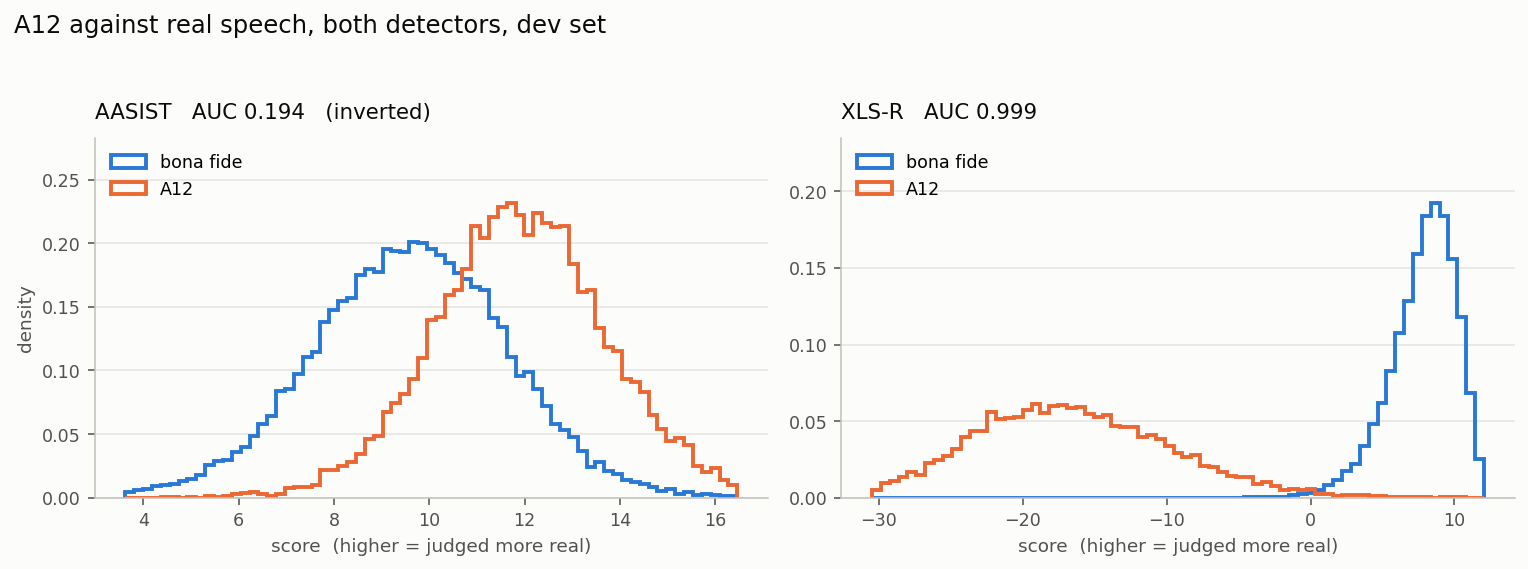



DONE. Paste the output back.


In [ ]:
"""
CMPE 258 - inversion scan on dev, both detectors
================================================

A19 (eval) and A12 (dev) both push AASIST above 50% EER. Above chance means
the detector is not merely weak, it is backwards: it scores those spoofs as
MORE bona fide than real speech. One case is an anecdote. A pattern across
attacks, present in one architecture and absent in the other, is the RQ2
result.

What this does:
  1. SCAN      AUC for every dev attack under both detectors. AUC = P(a bona
               fide file outscores a spoof file). Below 0.5 is inverted.
  2. DEEP DIVE on the worst inverted attack: score quantiles, and whether the
               inversion holds per speaker or is driven by a subset.
  3. FIGURE    the two detectors side by side on that attack.

Run after dev_stage_check.py in the same notebook (reuses nothing; it reloads).
No audio, no GPU.
"""

import glob
import os

import numpy as np
import pandas as pd

SHRIYA_DIR = '/content/drive/MyDrive/shriya_aasist'
ZAHIRA_DIR = '/content/drive/MyDrive/XLS-R'     # add the trailing space if not renamed
PROTO_DIR = '/content/asvspoof5_protocols'

DETECTORS = {'AASIST': f'{SHRIYA_DIR}/scores/aasist_dev.tsv',
             'XLS-R':  f'{ZAHIRA_DIR}/scores/xlsr_dev.tsv'}

PROTO_COLS = ['SPEAKER_ID', 'FLAC_FILE_NAME', 'SPEAKER_GENDER', 'CODEC', 'CODEC_Q',
              'CODEC_SEED', 'ATTACK_TAG', 'ATTACK_LABEL', 'KEY', 'TMP']

C_BONA, C_ATK = '#2a78d6', '#eb6834'      # validated categorical slots 1 and 2


def auc(pos, neg):
    """P(a random pos outscores a random neg), ties half."""
    from scipy.stats import rankdata
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    n1 = len(pos)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * len(neg)))


def load():
    hits = glob.glob(os.path.join(PROTO_DIR, '**', 'ASVspoof5.dev.track_1.tsv'),
                     recursive=True)
    if not hits:
        raise FileNotFoundError('dev protocol missing - run dev_stage_check.py first')
    proto = pd.read_csv(hits[0], sep=r'\s+', header=None, names=PROTO_COLS, dtype=str)
    proto['filename'] = proto['FLAC_FILE_NAME']

    out = {}
    for name, path in DETECTORS.items():
        s = pd.read_csv(path, sep='\t', dtype={'filename': str})
        col = 'cm-score' if 'cm-score' in s.columns else s.columns[1]
        out[name] = s[['filename', col]].rename(columns={col: 'score'}).merge(
            proto[['filename', 'SPEAKER_ID', 'ATTACK_LABEL', 'KEY']], on='filename')
    return out


def scan(data):
    print('1. INVERSION SCAN - AUC per attack, both detectors')
    print('===================================================')
    print('  AUC = P(bona fide outscores the attack). < 0.5 means INVERTED.')
    rows = []
    for name, df in data.items():
        bona = df.loc[df.KEY == 'bonafide', 'score'].to_numpy()
        bona_med = float(np.median(bona))
        for a in sorted(df.loc[df.KEY == 'spoof', 'ATTACK_LABEL'].unique()):
            x = df.loc[(df.ATTACK_LABEL == a) & (df.KEY == 'spoof'), 'score'].to_numpy()
            rows.append({'detector': name, 'attack': a, 'n': len(x),
                         'AUC': round(auc(bona, x), 4),
                         'median_shift': round(float(np.median(x)) - bona_med, 2)})
    tab = pd.DataFrame(rows)

    wide = tab.pivot(index='attack', columns='detector', values='AUC')
    print()
    print(wide.to_string())

    inv = tab[tab.AUC < 0.5]
    print('\n  INVERTED (AUC below 0.5):')
    if len(inv):
        for _, r in inv.sort_values('AUC').iterrows():
            print(f'    {r.detector:<8} {r.attack}   AUC {r.AUC:.4f}   '
                  f'scores {r.median_shift:+.2f} vs bona fide median   n={r.n:,}')
    else:
        print('    none')

    near = tab[(tab.AUC >= 0.5) & (tab.AUC < 0.6)]
    if len(near):
        print('\n  NEAR CHANCE (0.5 - 0.6, no usable signal):')
        for _, r in near.sort_values('AUC').iterrows():
            print(f'    {r.detector:<8} {r.attack}   AUC {r.AUC:.4f}   n={r.n:,}')

    print('\n  Count of inverted attacks per detector:')
    for name in data:
        n = int(((tab.detector == name) & (tab.AUC < 0.5)).sum())
        total = int((tab.detector == name).sum())
        print(f'    {name:<8} {n} of {total}')
    print('\n  One architecture inverting where the other does not is a')
    print('  qualitative difference, not a difference of degree. That is the')
    print('  RQ2 claim worth making.')
    return tab


def deep_dive(data, attack):
    print(f'\n\n2. DEEP DIVE ON {attack}')
    print('=' * (18 + len(attack)))
    for name, df in data.items():
        bona = df.loc[df.KEY == 'bonafide', 'score'].to_numpy()
        x = df.loc[(df.ATTACK_LABEL == attack) & (df.KEY == 'spoof'), 'score'].to_numpy()
        if not len(x):
            continue
        a = auc(bona, x)
        print(f'\n  {name}   AUC {a:.4f}'
              + ('   INVERTED' if a < 0.5 else ''))
        for lab, v in [('bona fide', bona), (attack, x)]:
            q = np.percentile(v, [5, 25, 50, 75, 95])
            print(f'    {lab:<12} n={len(v):>7,}   p5 {q[0]:>7.2f}  p25 {q[1]:>7.2f}  '
                  f'median {q[2]:>7.2f}  p75 {q[3]:>7.2f}  p95 {q[4]:>7.2f}')

        # per speaker
        sub = df[(df.ATTACK_LABEL == attack) & (df.KEY == 'spoof')]
        bona_rows = df[df.KEY == 'bonafide']
        per = []
        for spk, grp in sub.groupby('SPEAKER_ID'):
            b = bona_rows.loc[bona_rows.SPEAKER_ID == spk, 'score'].to_numpy()
            if len(b) >= 3 and len(grp) >= 3:
                per.append(auc(b, grp['score'].to_numpy()))
        if per:
            per = np.array(per)
            print(f'    speakers checked {len(per)};  '
                  f'{(per < 0.5).mean():.1%} show the inversion;  '
                  f'median speaker AUC {np.median(per):.3f}')


def plot(data, attack, save_to=None):
    import matplotlib.pyplot as plt

    names = list(data.keys())
    fig, axes = plt.subplots(1, len(names), figsize=(11, 4.1), dpi=140)
    fig.patch.set_facecolor('#fcfcfb')
    if len(names) == 1:
        axes = [axes]

    for ax, name in zip(axes, names):
        df = data[name]
        bona = df.loc[df.KEY == 'bonafide', 'score'].to_numpy()
        x = df.loc[(df.ATTACK_LABEL == attack) & (df.KEY == 'spoof'), 'score'].to_numpy()
        lo, hi = np.percentile(np.concatenate([bona, x]), [0.3, 99.7])
        bins = np.linspace(lo, hi, 70)
        a = auc(bona, x)

        ax.set_facecolor('#fcfcfb')
        top = 0
        for lab, v, c in [('bona fide', bona, C_BONA), (attack, x, C_ATK)]:
            ax.hist(v, bins=bins, density=True, histtype='step', linewidth=2,
                    color=c, label=lab)
            h, _ = np.histogram(v, bins=bins, density=True)
            top = max(top, float(h.max()))
        ax.set_ylim(0, top * 1.22)
        ax.set_title(f'{name}   AUC {a:.3f}'
                     + ('   (inverted)' if a < 0.5 else ''),
                     fontsize=11, loc='left', color='#0b0b0b', pad=10)
        ax.set_xlabel('score  (higher = judged more real)', fontsize=9.5, color='#52514e')
        ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
        ax.set_axisbelow(True)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'):
            ax.spines[s].set_color('#c3c2b7')
        ax.tick_params(colors='#52514e', labelsize=9)
        ax.legend(frameon=False, fontsize=9, loc='upper left')
    axes[0].set_ylabel('density', fontsize=9.5, color='#52514e')
    fig.suptitle(f'{attack} against real speech, both detectors, dev set',
                 fontsize=12.5, x=0.012, ha='left', color='#0b0b0b')
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    if save_to:
        fig.savefig(save_to, bbox_inches='tight', facecolor=fig.get_facecolor())
        print(f'\n  figure saved: {save_to}')
    plt.show()


def main(attack='A12', save_to='/content/drive/MyDrive/258_fig_a12_inversion.png'):
    data = load()
    tab = scan(data)
    deep_dive(data, attack)
    plot(data, attack, save_to)
    print('\n\nDONE. Paste the output back.')
    return tab


if __name__ == '__main__':
    inversion_table = main()

## Reconnect Drive again

Zahira created the `ssl_detector/` folder after this notebook last mounted Drive,
and Colab caches the folder listing at mount time. Without a forced remount the
eval scores are invisible even though they are sitting there.

In [1]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


## The main table — shift decomposition across both detectors

This is the result the project was built to produce. It runs the full
decomposition — generator, adversarial and codec slices — separately for AASIST
and for XLS-R, with speaker-level confidence intervals on every cell.

The output is ordered so the fast answers arrive first:

- **Part 0** finds Zahira's eval score file and prints what's in the folder.
- **Part 1** validates both detectors (rows, duplicates, join coverage, score
  direction).
- **Part 2** is the inversion scan on the evaluation set. This answers the A19
  question in under a minute: does the XLS-R detector also get waveform-
  concatenation attacks backwards, or is that specific to AASIST?
- **Part 3** is the slow part, the bootstrap over every slice for both detectors.
- **Part 4** prints them side by side, and ends with the **spread within each
  shift type** — which is what actually answers "which shift breaks detectors",
  since a single worst cell tells you much less than the range.

In [2]:
"""
CMPE 258 - the main table: shift decomposition across BOTH detectors
====================================================================

Run in the same notebook. Remount Drive first - ssl_detector/ was created after
your last mount, so Colab will not see it otherwise:

    from google.colab import drive
    drive.flush_and_unmount()
    drive.mount('/content/drive', force_remount=True)

Order of output is deliberate:

  PART 0  find Zahira's eval score file (prints the folder so you can correct it)
  PART 1  load and validate both detectors on eval
  PART 2  INVERSION SCAN - fast, and answers the A19 question first
  PART 3  full shift decomposition, both detectors, with bootstrap intervals
  PART 4  side-by-side summary

Part 3 is the slow one. Parts 0-2 finish in under a minute, so the headline
result is on screen long before the bootstrap completes.
"""

import glob
import json
import os

import numpy as np
import pandas as pd

# ------------------------------------------------------------------- config
SHRIYA_DIR = '/content/drive/MyDrive/shriya_aasist'
ZAHIRA_DIR = '/content/drive/MyDrive/XLS-R'
SSL_SCORES = f'{ZAHIRA_DIR}/ssl_detector/scores'

AASIST_EVAL = f'{SHRIYA_DIR}/scores/aasist_eval.tsv'
PROTO_EVAL = f'{SHRIYA_DIR}/keys/ASVspoof5.eval.track_1.tsv'

PROTO_COLS = ['SPEAKER_ID', 'FLAC_FILE_NAME', 'SPEAKER_GENDER', 'CODEC', 'CODEC_Q',
              'CODEC_SEED', 'ATTACK_TAG', 'ATTACK_LABEL', 'KEY', 'TMP']
EXPECTED_ROWS = 680774

UNCODED = '-'
ATTACK = 'ATTACK_LABEL'
SEED = 258
B_BOOT = 200          # raise to 1000 for the final table

FAMILIES = {
    'legacy unit selection': ['A19'],
    'zero-shot TTS':         ['A17', 'A21', 'A22', 'A28', 'A29'],
    'voice conversion':      ['A24', 'A25', 'A26'],
}
MALAFIDE = {'A18': 'A17', 'A30': 'A17', 'A20': None, 'A23': None}
MALACOPULA = ['A27', 'A31', 'A32']


# ---------------------------------------------------------------------- math
def _eer(tar, non):
    if tar.size == 0 or non.size == 0:
        return np.nan
    n = tar.size + non.size
    s = np.concatenate((tar, non))
    lab = np.concatenate((np.ones(tar.size), np.zeros(non.size)))
    o = np.argsort(s, kind='mergesort')
    lab = lab[o]
    ts = np.cumsum(lab)
    ns = non.size - (np.arange(1, n + 1) - ts)
    frr = np.concatenate((np.atleast_1d(0.0), ts / tar.size))
    far = np.concatenate((np.atleast_1d(1.0), ns / non.size))
    i = np.argmin(np.abs(frr - far))
    return 100 * float((frr[i] + far[i]) / 2)


def eer_pct(df):
    return _eer(df.loc[df.KEY == 'bonafide', 'score'].to_numpy(),
                df.loc[df.KEY == 'spoof', 'score'].to_numpy())


def auc_val(pos, neg):
    from scipy.stats import rankdata
    if not len(pos) or not len(neg):
        return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))


def bootstrap(df, b=B_BOOT, seed=SEED):
    """95% CI by resampling speakers."""
    spk = df.SPEAKER_ID.to_numpy()
    sc = df['score'].to_numpy()
    isb = (df.KEY == 'bonafide').to_numpy()
    uniq, inv = np.unique(spk, return_inverse=True)
    tar_by = [sc[(inv == i) & isb] for i in range(len(uniq))]
    non_by = [sc[(inv == i) & ~isb] for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(b):
        p = rng.integers(0, len(uniq), len(uniq))
        v = _eer(np.concatenate([tar_by[i] for i in p]),
                 np.concatenate([non_by[i] for i in p]))
        if np.isfinite(v):
            vals.append(v)
    if not vals:
        return np.nan, np.nan
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


# ------------------------------------------------------------------- PART 0
def find_ssl_eval():
    print('PART 0. LOCATE THE XLS-R EVAL SCORES')
    print('=====================================')
    if not os.path.isdir(SSL_SCORES):
        print(f'  [FAIL] {SSL_SCORES} not found.')
        print('  Remount Drive (ssl_detector/ was created after your last mount),')
        print('  then check the path. Parent listing:')
        parent = os.path.dirname(SSL_SCORES)
        if os.path.isdir(parent):
            print('   ', os.listdir(parent))
        return None
    files = sorted(os.listdir(SSL_SCORES))
    print(f'  {SSL_SCORES} contains:')
    for f in files:
        size = os.path.getsize(os.path.join(SSL_SCORES, f)) / 1e6
        print(f'    {f:<45} {size:8.1f} MB')

    evals = [f for f in files if 'eval' in f.lower() and f.endswith(('.tsv', '.csv'))]
    if not evals:
        print('  [FAIL] no eval score file here. Set the path by hand.')
        return None
    # prefer an ensemble file (no "seed" in the name) over a per-seed one
    ensemble = [f for f in evals if 'seed' not in f.lower()]
    pick = (ensemble or evals)[0]
    print(f'\n  using: {pick}'
          + ('' if ensemble else '   [NOTE] this is a per-seed file, not the ensemble'))
    return os.path.join(SSL_SCORES, pick)


# ------------------------------------------------------------------- PART 1
def load(ssl_path):
    print('\n\nPART 1. LOAD AND VALIDATE')
    print('==========================')
    proto = pd.read_csv(PROTO_EVAL, sep=r'\s+', header=None, names=PROTO_COLS, dtype=str)
    proto['filename'] = proto['FLAC_FILE_NAME']
    print(f'  protocol              {len(proto):>8,} rows')

    out = {}
    for name, path in [('AASIST', AASIST_EVAL), ('XLS-R', ssl_path)]:
        raw = pd.read_csv(path, sep='\t', dtype={'filename': str})
        cand = ['cm-score', 'cm_score', 'score', 'logit_bonafide']
        col = next((c for c in cand if c in raw.columns), None)
        if col is None:
            num = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c])]
            col = num[0] if num else None
        print(f'\n  {name}')
        print(f'    columns: {list(raw.columns)}')
        if col != 'cm-score':
            print(f'    [NOTE] using "{col}" as the score column')
        df = raw[['filename', col]].rename(columns={col: 'score'}).merge(
            proto[['filename', 'KEY', 'SPEAKER_ID', 'CODEC', 'CODEC_SEED', ATTACK]],
            on='filename')
        for lab, cond, det in [
                ('row count', len(raw) == EXPECTED_ROWS, f'{len(raw):,}'),
                ('no duplicates', not raw.filename.duplicated().any(), ''),
                ('join coverage 100%', len(df) == len(raw), f'{len(df):,} of {len(raw):,}'),
                ('scores finite', np.isfinite(df.score).all(), '')]:
            print(f'    [{"PASS" if cond else "FAIL"}] {lab}{("  " + det) if det else ""}')
        e = eer_pct(df)
        a = auc_val(df.loc[df.KEY == 'bonafide', 'score'].to_numpy(),
                    df.loc[df.KEY == 'spoof', 'score'].to_numpy())
        print(f'    pooled eval EER {e:6.2f}%   AUC {a:.4f}'
              + ('   [WARN] AUC < 0.5, scores may be sign-flipped' if a < 0.5 else ''))
        out[name] = df
    return out


# ------------------------------------------------------------------- PART 2
def inversion_scan(data):
    print('\n\nPART 2. INVERSION SCAN ON EVAL  (the A19 question)')
    print('==================================================')
    print('  AUC = P(bona fide outscores the attack). Below 0.5 means the')
    print('  detector is BACKWARDS on that attack, not merely weak.\n')
    rows = []
    for name, df in data.items():
        unc = df[df.CODEC == UNCODED]
        bona = unc.loc[unc.KEY == 'bonafide', 'score'].to_numpy()
        bona_med = float(np.median(bona))
        for a in sorted(unc.loc[unc.KEY == 'spoof', ATTACK].unique()):
            x = unc.loc[(unc[ATTACK] == a) & (unc.KEY == 'spoof'), 'score'].to_numpy()
            rows.append({'detector': name, 'attack': a, 'n': len(x),
                         'AUC': round(auc_val(bona, x), 4),
                         'med_shift': round(float(np.median(x)) - bona_med, 2)})
    tab = pd.DataFrame(rows)
    print(tab.pivot(index='attack', columns='detector', values='AUC').to_string())

    print('\n  INVERTED (AUC < 0.5):')
    inv = tab[tab.AUC < 0.5].sort_values('AUC')
    if len(inv):
        for _, r in inv.iterrows():
            print(f'    {r["detector"]:<8} {r["attack"]}   AUC {r["AUC"]:.4f}   '
                  f'median {r["med_shift"]:+.2f} vs bona fide   n={r["n"]:,}')
    else:
        print('    none')
    print('\n  per detector:', {n: int(((tab.detector == n) & (tab.AUC < 0.5)).sum())
                                for n in data})

    # the specific question
    print('\n  A19 (waveform concatenation, the sibling of dev A12):')
    for name in data:
        r = tab[(tab.detector == name) & (tab.attack == 'A19')]
        if len(r):
            v = float(r['AUC'].iloc[0])
            verdict = 'INVERTED' if v < 0.5 else ('near chance' if v < 0.6 else 'handled')
            print(f'    {name:<8} AUC {v:.4f}   {verdict}')
    print('\n  If XLS-R handles A19 while AASIST inverts, the blind spot is')
    print('  confirmed on both concatenation attacks across both partitions.')
    print('  If BOTH invert, vocoder-free synthesis is hard for artifact-based')
    print('  detectors generally - a different and also publishable claim.')
    return tab


# ------------------------------------------------------------------- PART 3
def crossed(df):
    coded = df[df.CODEC != UNCODED]
    n = coded.CODEC.nunique()
    sizes = coded.CODEC_SEED.value_counts()
    return coded[coded.CODEC_SEED.isin(sizes[sizes == n].index)]


def decompose(data):
    print('\n\nPART 3. SHIFT DECOMPOSITION, BOTH DETECTORS')
    print('============================================')
    print(f'  bootstrap B={B_BOOT}; this is the slow part.\n')
    rows = []
    for name, df in data.items():
        print(f'  {name}...')
        unc = df[df.CODEC == UNCODED]
        bona = unc[unc.KEY == 'bonafide']
        cb = crossed(df)

        def add(slice_name, kind, sub):
            lo, hi = bootstrap(sub)
            rows.append({'detector': name, 'slice': slice_name, 'kind': kind,
                         'n_spoof': int((sub.KEY == 'spoof').sum()),
                         'EER_%': round(eer_pct(sub), 2),
                         'lo': round(lo, 2), 'hi': round(hi, 2)})

        add('ALL attacks, uncoded', 'reference', unc)
        for fam, atks in FAMILIES.items():
            sel = unc[(unc[ATTACK].isin(atks)) & (unc.KEY == 'spoof')]
            if len(sel):
                add(f'{fam} ({"+".join(atks)})', 'generator', pd.concat([bona, sel]))
        for atk, src in MALAFIDE.items():
            sel = unc[(unc[ATTACK] == atk) & (unc.KEY == 'spoof')]
            if len(sel):
                lab = f'Malafide {atk}' + (f' (from {src})' if src else ' (src in dev)')
                add(lab, 'adversarial', pd.concat([bona, sel]))
        sel = unc[(unc[ATTACK].isin(MALACOPULA)) & (unc.KEY == 'spoof')]
        if len(sel):
            add(f'Malacopula ({"+".join(MALACOPULA)})', 'adversarial', pd.concat([bona, sel]))
        for atk, src in MALAFIDE.items():
            if src is None:
                continue
            s_sel = unc[(unc[ATTACK] == src) & (unc.KEY == 'spoof')]
            a_sel = unc[(unc[ATTACK] == atk) & (unc.KEY == 'spoof')]
            if len(s_sel) and len(a_sel):
                add(f'  source {src} alone', 'adv-paired', pd.concat([bona, s_sel]))
                add(f'  -> {atk} adversarial', 'adv-paired', pd.concat([bona, a_sel]))
        for c in sorted(cb.CODEC.unique()):
            add(f'codec {c}', 'codec', cb[cb.CODEC == c])
    return pd.DataFrame(rows)


# ------------------------------------------------------------------- PART 4
def report(tab):
    print('\n\nPART 4. SIDE BY SIDE  (EER %, 95% speaker-level CI)')
    print('===================================================')
    for kind in ['reference', 'generator', 'adversarial', 'adv-paired', 'codec']:
        part = tab[tab['kind'] == kind]
        if not len(part):
            continue
        print(f'\n{kind.upper()}')
        for sl in part['slice'].unique():
            line = f'  {sl:<38}'
            for det in tab.detector.unique():
                r = part[(part['slice'] == sl) & (part.detector == det)]
                if len(r):
                    r = r.iloc[0]
                    line += f'  {det} {r["EER_%"]:>6.2f} [{r["lo"]:>5.2f},{r["hi"]:>5.2f}]'
            print(line)

    print('\n\n  SPREAD WITHIN EACH SHIFT TYPE  (what answers "which shift breaks it")')
    for det in tab.detector.unique():
        print(f'\n  {det}')
        for kind in ['generator', 'adversarial', 'codec']:
            p = tab[(tab.detector == det) & (tab['kind'] == kind)]
            if len(p):
                print(f'    {kind:<13} {p["EER_%"].min():6.2f} to {p["EER_%"].max():6.2f}'
                      f'   (spread {p["EER_%"].max() - p["EER_%"].min():6.2f} points)')


def main():
    ssl_path = find_ssl_eval()
    if ssl_path is None:
        return None
    data = load(ssl_path)
    inv = inversion_scan(data)
    tab = decompose(data)
    report(tab)
    out = '/content/drive/MyDrive/258_results_both_detectors.csv'
    tab.to_csv(out, index=False)
    print(f'\n  saved: {out}')
    print('\n\nDONE. Paste the output back.')
    return tab, inv


if __name__ == '__main__':
    both_table, inversion_table = main()

PART 0. LOCATE THE XLS-R EVAL SCORES
  /content/drive/MyDrive/XLS-R/ssl_detector/scores contains:
    xlsr_dev.tsv                                       6.3 MB
    xlsr_dev_calibrated.tsv                           13.0 MB
    xlsr_dev_seed_258.tsv                              6.3 MB
    xlsr_dev_seed_259.tsv                              6.3 MB
    xlsr_dev_seed_260.tsv                              6.3 MB
    xlsr_eval.tsv                                     30.5 MB
    xlsr_eval_calibrated.tsv                          39.0 MB
    xlsr_eval_seed_258.tsv                            30.5 MB
    xlsr_eval_seed_259.tsv                            30.5 MB
    xlsr_eval_seed_260.tsv                            30.5 MB

  using: xlsr_eval.tsv


PART 1. LOAD AND VALIDATE
  protocol               680,774 rows

  AASIST
    columns: ['filename', 'cm-score', 'logit_spoof', 'logit_bonafide']
    [PASS] row count  680,774
    [PASS] no duplicates
    [PASS] join coverage 100%  680,774 of 680,774
    [P

---

## What this notebook found

### 1. The ranking of shift types reverses between architectures

This is the main result.

| Shift type | AASIST spread | XLS-R spread |
|---|---|---|
| generator | 54.06 points | 0.72 points |
| adversarial | 32.33 points | 6.93 points |
| codec | 12.67 points | **16.61 points** |

AASIST's worst failure mode is which generator produced the spoof, and its
mildest is codec. For XLS-R it is exactly inverted: the generator effect all but
disappears (a 75-fold reduction in spread) while codec becomes the dominant
failure. The SSL front end does not make the detector uniformly better — it
removes one failure mode and leaves another standing.

### 2. AASIST is sign-inverted on vocoder-free synthesis; XLS-R is not

A19 (eval) and A12 (dev) are the only two attacks in the entire benchmark built
by **waveform concatenation** rather than a neural vocoder — every other attack
uses HiFi-GAN, BigVGAN, WaveGrad, WaveGlow or WaveNet. They are the only two
attacks AASIST gets *backwards*, scoring the fakes as more real than genuine
speech:

| | AASIST | XLS-R |
|---|---|---|
| A19 (eval) | AUC 0.347 — inverted | AUC 0.9998 |
| A12 (dev) | AUC 0.194 — inverted, 99.2% of 386 speakers | AUC 0.9988 |

Unit selection stitches together recorded chunks of real human speech, so there
are no vocoder artifacts to detect — and the stitched audio is *cleaner* than our
crowdsourced recordings, which were not made in a studio. That is an
architecture-specific blind spot with an identifiable cause, not a difference of
degree.

### 3. Adversarial post-processing is the largest single controlled effect

A17 is detected easily. A18 is the same generator with a Malafide filter applied —
same speakers, same codec condition, only the adversarial step differs:

| | A17 | → A18 | factor |
|---|---|---|---|
| AASIST | 3.54% | 46.83% | 13× |
| XLS-R | 0.05% | 2.27% | 45× |

XLS-R is far better in absolute terms, but it degrades *more* in relative terms.
It is not adversarially robust — it starts from a much lower base. Worth stating
plainly, because "SSL solves it" is the wrong conclusion. Note also that Malafide
was optimised against an AASIST countermeasure, so for XLS-R these are transfer
attacks, which usually weaken considerably. It still cost a factor of 45.

### 4. The two detectors break on different codecs

AASIST's worst are C08, C09 and C10 at roughly 35%. XLS-R's worst are C07 at
18.64% and C04 at 15.36%, while C08 and C09 barely trouble it. They are not
simply differently robust — the specific encodings that defeat them differ.

---

### Still open

- Which codec types C07 and C04 actually are (turns finding 4 into an explanation)
- The VAD-trimmed control on the codec slice — our pre-registered check that the
  codec effect is not a non-speech shortcut. Codec is now the headline result for
  XLS-R, so this control is load-bearing.
- Paired per-utterance codec deltas, now that `CODEC_SEED` pairing is confirmed
- Per-slice calibration and abstention analysis (RQ3)
- DFADD folded into the same table